Dataset Shape: (4998, 141)
Class Distribution:
140
1.0    2919
0.0    2079
Name: count, dtype: int64
Normal Training Shape: (2335, 140, 1)
Testing Shape: (1000, 140, 1)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 140, 16)             │              64 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 70, 16)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 70, 8)               │             392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 35, 8)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_2 (Conv1D)                    │ (None, 35, 8)               │             200 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d (UpSampling1D)         │ (None, 70, 8)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_3 (Conv1D)                    │ (None, 70, 16)              │             400 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling1d_1 (UpSampling1D)       │ (None, 140, 16)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_4 (Conv1D)                    │ (None, 140, 1)              │              49 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,105 (4.32 KB)

 Trainable params: 1,105 (4.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0507 - mae: 0.1602 - val_loss: 0.0101 - val_mae: 0.0737
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0064 - mae: 0.0522 - val_loss: 0.0043 - val_mae: 0.0417
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0038 - mae: 0.0394 - val_loss: 0.0031 - val_mae: 0.0367
Epoch 4/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0025 - mae: 0.0347 - val_loss: 0.0020 - val_mae: 0.0322
Epoch 5/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0019 - mae: 0.0315 - val_loss: 0.0017 - val_mae: 0.0301
Epoch 6/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0017 - mae: 0.0300 - val_loss: 0.0016 - val_mae: 0.0290
Epoch 7/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0016 - mae: 0.0289 - val_loss: 0.0015 - val_mae: 0.0281
Epoch 8/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0015 - mae: 0.0281 - val_loss: 0.0014 - val_mae: 0.0276
Epoch 9/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0014 - mae: 

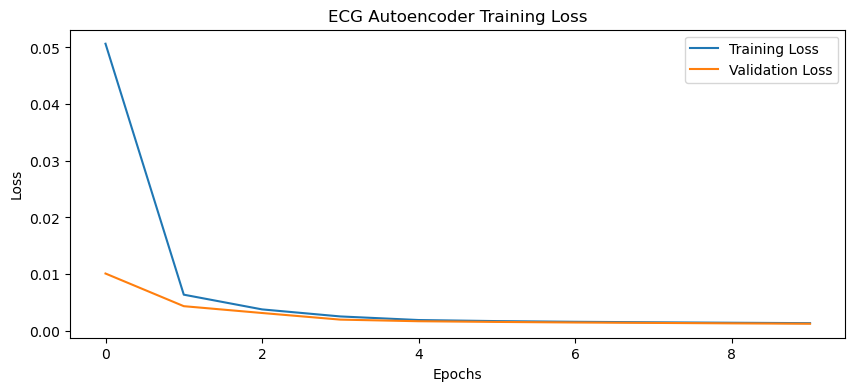

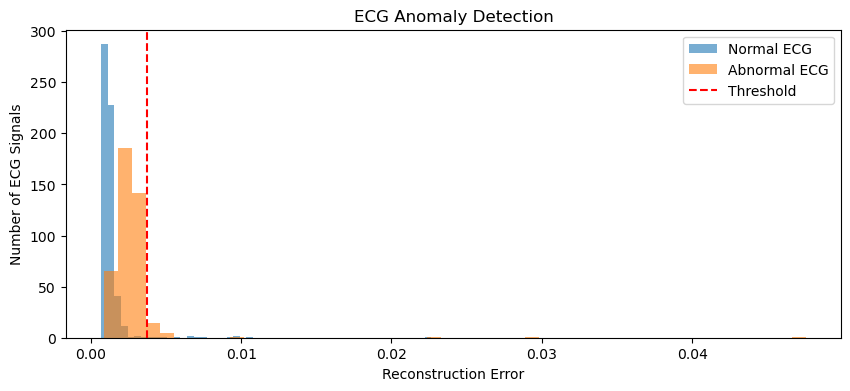

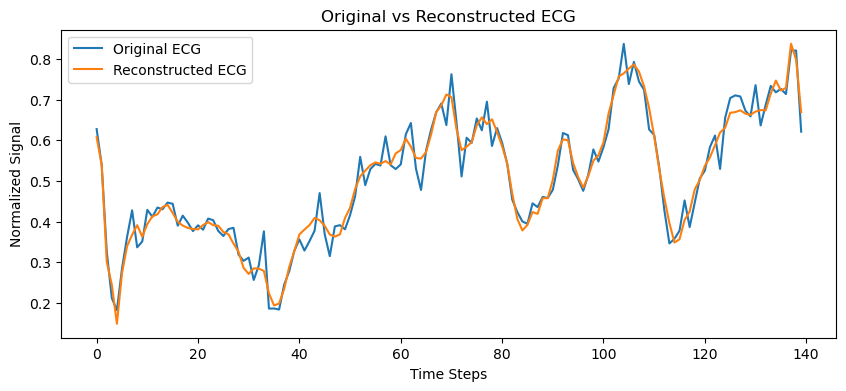

In [1]:
# Assignment 3B: ECG Anomaly Detection Using CNN Autoencoder

# Step 1: Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    UpSampling1D, Dense
)
from tensorflow.keras.optimizers import Adam


# Step 2: Load Dataset

data = pd.read_csv("ecg.csv", header=None)

print("Dataset Shape:", data.shape)
print("Class Distribution:")
print(data.iloc[:, -1].value_counts())


# Step 3: Separate Features and Labels

X = data.iloc[:, :-1].values

# Original labels:
# 1 = Normal
# 0 = Abnormal

# Convert to anomaly detection labels:
# 0 = Normal
# 1 = Abnormal

y = (data.iloc[:, -1].values == 0).astype(int)


# Step 4: Split Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# Step 5: Select Only Normal ECG Signals

X_train_normal = X_train[y_train == 0]


# Step 6: Normalize ECG Signals

scaler = MinMaxScaler()

X_train_normal = scaler.fit_transform(X_train_normal)
X_test = scaler.transform(X_test)


# Step 7: Reshape for CNN

X_train_normal = X_train_normal.reshape(-1, 140, 1)
X_test = X_test.reshape(-1, 140, 1)

print("Normal Training Shape:", X_train_normal.shape)
print("Testing Shape:", X_test.shape)


# Step 8: Build CNN Autoencoder

model = Sequential([
    Input(shape=(140, 1)),

    # Encoder
    Conv1D(16, 3, activation="relu", padding="same"),
    MaxPooling1D(2),

    Conv1D(8, 3, activation="relu", padding="same"),
    MaxPooling1D(2),

    # Decoder
    Conv1D(8, 3, activation="relu", padding="same"),
    UpSampling1D(2),

    Conv1D(16, 3, activation="relu", padding="same"),
    UpSampling1D(2),

    Conv1D(1, 3, activation="linear", padding="same")
])


# Step 9: Compile Model

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

model.summary()


# Step 10: Train Autoencoder

history = model.fit(
    X_train_normal,
    X_train_normal,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    shuffle=True
)


# Step 11: Calculate Training Reconstruction Error

train_predictions = model.predict(
    X_train_normal,
    verbose=0
)

train_error = np.mean(
    np.square(X_train_normal - train_predictions),
    axis=(1, 2)
)


# Step 12: Set Anomaly Threshold

threshold = np.percentile(train_error, 99)

print("Anomaly Threshold:", threshold)


# Step 13: Calculate Testing Reconstruction Error

test_predictions = model.predict(X_test, verbose=0)

test_error = np.mean(
    np.square(X_test - test_predictions),
    axis=(1, 2)
)


# Step 14: Detect Anomalies

y_pred = (test_error > threshold).astype(int)


# Step 15: Evaluate Model

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


# Step 16: Plot Training Loss

plt.figure(figsize=(10, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("ECG Autoencoder Training Loss")
plt.legend()
plt.show()


# Step 17: Plot Reconstruction Errors

plt.figure(figsize=(10, 4))

plt.hist(
    test_error[y_test == 0],
    bins=50,
    alpha=0.6,
    label="Normal ECG"
)

plt.hist(
    test_error[y_test == 1],
    bins=50,
    alpha=0.6,
    label="Abnormal ECG"
)

plt.axvline(
    threshold,
    color="red",
    linestyle="--",
    label="Threshold"
)

plt.xlabel("Reconstruction Error")
plt.ylabel("Number of ECG Signals")
plt.title("ECG Anomaly Detection")
plt.legend()
plt.show()


# Step 18: Display Original and Reconstructed ECG

plt.figure(figsize=(10, 4))

plt.plot(
    X_test[0].flatten(),
    label="Original ECG"
)

plt.plot(
    test_predictions[0].flatten(),
    label="Reconstructed ECG"
)

plt.xlabel("Time Steps")
plt.ylabel("Normalized Signal")
plt.title("Original vs Reconstructed ECG")
plt.legend()
plt.show()